# Weisfeiler-Lehman Graph Kernels on REDDIT-BINARY
### Re-implementing the WL subtree kernel from scratch, and improving it with principled modifications

**Course:** 23CSE479 – Machine Learning with Graphs
**Textbook:** W. L. Hamilton, *Graph Representation Learning* (2020) – §2.1.2 (WL kernel, Eq. 2.6) and §7.3 (1-WL algorithm, Eq. 7.60)

---

**What this notebook does, in one paragraph.**
We classify Reddit discussion threads (graphs where nodes are users and edges mean *"replied to"*) into two
communities using the Weisfeiler-Lehman (WL) kernel. REDDIT-BINARY graphs have **no node labels**, so the WL algorithm
needs us to *invent* starting labels. We first re-implement the textbook WL kernel exactly (degree as the starting
label, linear kernel), verify it against the textbook's own worked example, and then study three
places where the algorithm can be modified:

| Where in WL | What we vary | Textbook / paper link |
|---|---|---|
| **Step 1 – initial labels** $l^{(0)}(v)$ | uniform, degree, **log-binned degree**, clustering coefficient, PageRank, combined | Hamilton §2.1.1, Eq. 2.5; PageRank (Unit 2) |
| **Step 2 – relabelling rule** | neighbours only (Eq. 2.6) vs. own label + neighbours (Eq. 7.60); number of iterations $h$ | Hamilton §2.1.2, §7.3.3 |
| **Step 3 – comparing histograms** | linear (original), cosine-normalised, histogram-intersection (WL-OA), **RBF on WL features** | Shervashidze et al. 2011; Kriege et al. 2016 |

Everything mathematical (WL hashing, feature histograms, Gram matrices, normalisation, intersection, RBF distances,
PageRank power iteration, clustering coefficients, kernel PCA, accuracy/F1, significance test) is written out
directly with NumPy so the mathematics is visible. Only the SVM solver (scikit-learn `SVC`) and plotting come from libraries.

**Contents**
1. Setup
2. The dataset
3. The WL kernel – theory
4. Implementation (initial labels → WL refinement → feature map → kernels)
5. Correctness tests (textbook Fig. 7.2 & 7.3, permutation invariance, independent cross-check, PSD)
6. Evaluation protocol (nested cross-validation)
7. Feature extraction
8. Baseline: the textbook WL kernel
9. Experiment 1 – initial labels
10. Experiment 2 – relabelling rule & depth
11. Experiment 3 – how histograms are compared
12. Final ablation: from baseline to best, one change at a time
13. Why it works – visual intuition
14. Summary of results
15. Limitations, conclusion, references

## 1. Setup
Runtime for the whole notebook is about 50–60 minutes on a 16-core laptop (8 parallel workers). Almost all of it is the nested
cross-validation of §12, which fits roughly 100k SVMs.

In [1]:
import time, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import networkx as nx          # used ONLY for drawing graphs and as an independent cross-check of our WL
from sklearn.svm import SVC     # the SVM solver; every kernel it receives is computed by hand below
from sklearn.model_selection import StratifiedKFold
from joblib import Parallel, delayed

SEED = 42
DATA_DIR = Path("data/raw/REDDIT-BINARY")
FIG_DIR, RES_DIR = Path("figures"), Path("results")
FIG_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(exist_ok=True)

# Colour palette (validated categorical palette, fixed order) and plot style
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GREY = "#9a9994"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titleweight": "bold", "font.size": 10, "lines.linewidth": 2, "lines.markersize": 6,
    "legend.frameon": False,
})
T_START = time.time()
print("numpy", np.__version__, "| networkx", nx.__version__)

numpy 2.3.1 | networkx 3.7


## 2. The dataset: REDDIT-BINARY

REDDIT-BINARY (Yanardag & Vishwanathan, 2015; distributed with TUDataset) contains **2,000 threads** from four
popular subreddits. Two are *question/answer* communities (e.g. IAmA, AskReddit) and two are *discussion*
communities (e.g. TrollXChromosomes, atheism). Each thread is a graph:

* **node** = a user who took part in the thread,
* **edge** $\{u,v\}$ = one of the two users replied to the other.

The task is to predict the community type from the **shape of the conversation only**. There are no node labels and no text.
(The dataset files do not document which numeric label, −1 or +1, is Q&A, so we report classes as −1 / +1.)

**File format (TU format).**
* `_A.txt`: one edge per line, as global node ids.
* `_graph_indicator.txt`: the graph each node belongs to.
* `_graph_labels.txt`: the class of each graph.

We store the whole dataset as one big **block-diagonal adjacency matrix**
$A\in\{0,1\}^{N\times N}$ with $A_{uv}=1 \iff \{u,v\}\in E$. Each graph is one block, and node degrees are row sums: $d_v=\sum_u A_{uv}$.

In [2]:
edges    = pd.read_csv(DATA_DIR / "REDDIT-BINARY_A.txt", header=None).to_numpy(np.int64) - 1    # 0-based node ids
graph_of = np.loadtxt(DATA_DIR / "REDDIT-BINARY_graph_indicator.txt", dtype=np.int64) - 1        # graph_of[v] = graph id
y        = np.loadtxt(DATA_DIR / "REDDIT-BINARY_graph_labels.txt", dtype=np.int64)               # class of each graph

N, G = len(graph_of), len(y)
edges = edges[edges[:, 0] != edges[:, 1]]                       # drop self-loops (none expected)

# A_uv = 1 iff {u,v} is an edge. Symmetrise (A + A^T) and clip to {0,1} so the graph is simple and undirected.
A = sp.csr_matrix((np.ones(len(edges), np.int32), (edges[:, 0], edges[:, 1])), shape=(N, N))
A = A + A.T
A.data[:] = 1
A.sort_indices()

deg      = np.asarray(A.sum(axis=1)).ravel()                    # d_v = sum_u A_uv
n_nodes  = np.bincount(graph_of, minlength=G)                   # |V_g|
n_edges  = np.bincount(graph_of, weights=deg, minlength=G) / 2  # |E_g| = (1/2) sum_{v in g} d_v (handshake lemma)
nbrs     = np.split(A.indices, A.indptr[1:-1])                  # N(v) for every node, read off the CSR rows of A
max_deg  = np.zeros(G); np.maximum.at(max_deg, graph_of, deg)

print(f"graphs: {G}   nodes: {N:,}   undirected edges: {int(n_edges.sum()):,}")
print("class balance:", dict(Counter(y.tolist())))
print("isolated nodes (d_v = 0):", int((deg == 0).sum()))

graphs: 2000   nodes: 859,254   undirected edges: 995,508
class balance: {1: 1000, -1: 1000}
isolated nodes (d_v = 0): 21


In [3]:
rows = []
for c in [-1, 1]:
    m = y == c
    rows.append({"class": c, "graphs": int(m.sum()),
                 "avg nodes": n_nodes[m].mean(), "avg edges": n_edges[m].mean(),
                 "avg degree": (2 * n_edges[m] / n_nodes[m]).mean(),
                 "avg max degree": max_deg[m].mean(),
                 "hub share  max_deg / n": (max_deg[m] / n_nodes[m]).mean(),
                 "edge density": (2 * n_edges[m] / (n_nodes[m] * (n_nodes[m] - 1))).mean(),
                 "trees (|E| = |V|-1)": f"{(n_edges[m] == n_nodes[m] - 1).mean():.1%}"})
stats = pd.DataFrame(rows).set_index("class")
stats.to_csv(RES_DIR / "dataset_stats.csv")
stats.round(3)

,graphs,avg nodes,avg edges,avg degree,avg max degree,hub share max_deg / n,edge density,trees (|E| = |V|-1)
class,,,,,,,,
-1,1000,641.252,735.951,2.406,336.256,0.508,0.012,0.1%
1,1000,218.002,259.557,2.270,98.438,0.460,0.032,5.9%


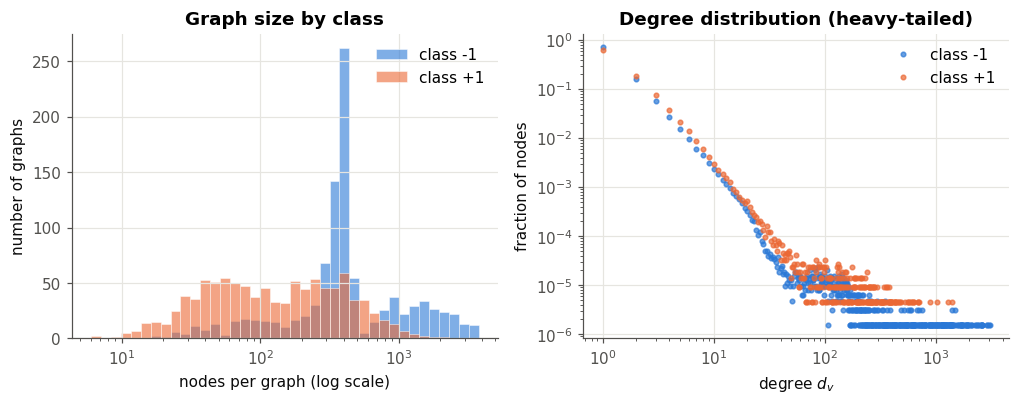

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.logspace(np.log10(n_nodes.min()), np.log10(n_nodes.max()), 40)
for c, col in zip([-1, 1], PAL):
    ax[0].hist(n_nodes[y == c], bins=bins, alpha=0.6, color=col, label=f"class {c:+d}", edgecolor="white", linewidth=0.5)
ax[0].set(xscale="log", xlabel="nodes per graph (log scale)", ylabel="number of graphs", title="Graph size by class")
ax[0].legend()

for c, col in zip([-1, 1], PAL):
    dv = deg[np.isin(graph_of, np.where(y == c)[0])]
    k, cnt = np.unique(dv, return_counts=True)
    ax[1].loglog(k, cnt / cnt.sum(), "o", ms=3, color=col, alpha=0.7, label=f"class {c:+d}")
ax[1].set(xlabel="degree $d_v$", ylabel="fraction of nodes", title="Degree distribution (heavy-tailed)")
ax[1].legend()
fig.savefig(FIG_DIR / "01_dataset.png"); plt.show()

**What the data tells us before any learning.**
* Class −1 threads are about **3× larger** than class +1 threads, so graph **size alone carries signal**.
  This will matter when we try normalising the kernel (§11).
* Degrees are **heavy-tailed**. Most users reply once (degree 1), while a few hub users (the original poster, or an
  AMA host) talk to hundreds of others. This becomes the key to the "initial labels" experiment.
* Almost no graph is a tree, but edges ≈ nodes, so the graphs are **tree-like with very few triangles**.

## 3. The Weisfeiler-Lehman kernel: theory

**WL colour refinement** (Hamilton §2.1.2 and §7.3.3):

1. **Initial labels.** Assign every node a label $l^{(0)}(v)$. Hamilton: *"In most graphs, this label is simply the degree."*
2. **Refinement.** For $i = 1,\dots,h$, give every node a new label by hashing the **multiset** of its neighbours' labels,
   either without its own label (Eq. 2.6) or with it (Eq. 7.60, the standard 1-WL):

$$l^{(i)}(v) = \mathrm{HASH}\Big(l^{(i-1)}(v),\ \{\!\{\, l^{(i-1)}(u) : u\in\mathcal N(v)\,\}\!\}\Big) \qquad\text{(Eq. 7.60)}$$

   `HASH` must be **injective**: two nodes get the same new label *iff* they had the same old label and the same multiset
   of neighbour labels. We implement it exactly as a dictionary (a "compression table") that is **shared by all graphs**,
   so the same neighbourhood pattern gets the same label in every graph. After $i$ iterations, $l^{(i)}(v)$ encodes the
   *rooted subtree* of depth $i$ around $v$.

3. **Feature map.** Count how often each label occurs in graph $G$:

$$\phi(G) = \Big[\, c\big(G,\sigma\big) \Big]_{\sigma\in\Sigma_0\cup\Sigma_1\cup\dots\cup\Sigma_h},\qquad c(G,\sigma)=\big|\{v\in V_G : l^{(i)}(v)=\sigma\}\big|$$

4. **WL subtree kernel** (Shervashidze et al., 2011): the number of matching subtree patterns between two graphs, i.e. the dot product of the histograms

$$k_{WL}^{(h)}(G,G') = \langle \phi(G),\phi(G')\rangle = \sum_{i=0}^{h}\ \sum_{\sigma\in\Sigma_i} c(G,\sigma)\,c(G',\sigma) .$$

Stacking all graphs' histograms as rows of a matrix $\Phi\in\mathbb N^{|\mathcal G|\times|\Sigma|}$ gives the whole Gram matrix in one product, $K=\Phi\Phi^\top$.
We plug $K$ into a kernel SVM, whose decision function is $f(G)=\sum_j \alpha_j y_j\,k(G_j,G)+b$.

**Why this matters on REDDIT.** With no node labels, *everything* WL knows comes from the labels we choose in Step 1
and from how Step 3 compares the counts. These are exactly the two places we modify.

## 4. Implementation

### 4.1 Step 1: initial node labels

Each function returns an integer label per node. Every option uses only structure, and each comes from the textbook or syllabus:

| name | $l^{(0)}(v)$ | idea |
|---|---|---|
| uniform | $1$ | no information; the classic choice for unlabelled graphs |
| degree | $d_v$ | Hamilton's default |
| **log-degree** | $1+\lfloor\log_2 d_v\rfloor$ | degree in *powers-of-two bins* (1 / 2–3 / 4–7 / 8–15 / …) |
| clustering | bin of $c_v=\dfrac{\lvert\{(v_1,v_2)\in E: v_1,v_2\in\mathcal N(v)\}\rvert}{\binom{d_v}{2}}$ | Hamilton Eq. 2.5 |
| PageRank | $\lfloor\log_2(n_G\, r_v)\rfloor$ | importance relative to a uniform node (Unit 2) |
| log-degree + clustering | pair (log-degree, clustering bin) | combined |

**Why bin the degree?** Raw degree is too *specific*: a user with 47 replies and one with 48 receive completely different labels.
After one WL step, the hub's label also depends on the exact degree of every neighbour, so almost no two graphs share
labels and the kernel sees no similarity. Logarithmic bins keep the meaningful distinction (leaf vs. active user vs. hub)
and throw away the noise. This is the main idea behind our improvement.

In [5]:
def init_uniform():
    return np.zeros(N, dtype=np.int64)                            # l0(v) = 1 for every v (encoded as 0)

def init_degree():
    return deg.astype(np.int64)                                   # l0(v) = d_v

def init_log_degree():
    out = np.zeros(N, dtype=np.int64)                             # d_v = 0 -> bin 0
    nz = deg > 0
    out[nz] = 1 + np.floor(np.log2(deg[nz])).astype(np.int64)     # 1 | 2-3 | 4-7 | 8-15 | ...
    return out

# ---- clustering coefficient, Hamilton Eq. 2.5 ------------------------------------------------
# triangles at v:  t_v = 1/2 * sum_{u in N(v)} |N(u) ∩ N(v)|   (each triangle at v is seen from both of its edges at v)
nbr_sets = [set(a.tolist()) for a in nbrs]
tri_twice = np.zeros(N)
for u in range(N):
    for v in nbrs[u]:
        if v > u:                                                 # each undirected edge once
            common = len(nbr_sets[u] & nbr_sets[v])
            tri_twice[u] += common
            tri_twice[v] += common
triangles = tri_twice / 2
pairs = deg * (deg - 1) / 2                                       # (d_v choose 2)
clust = np.divide(triangles, pairs, out=np.zeros(N), where=pairs > 0)

def init_clustering():
    # 0 = no closed triangle, then 4 equal-width bins of c_v in (0, 1]
    return np.where(clust == 0, 0, 1 + np.minimum(np.floor(clust * 4), 3)).astype(np.int64)

# ---- PageRank by power iteration on the whole block-diagonal graph -------------------------------
# r^(t+1)_v = (1 - alpha) / n_g  +  alpha * [ sum_{u in N(v)} r^(t)_u / d_u  +  (dangling mass of g) / n_g ]
# Each graph g is its own random walk. Isolated nodes (d_u = 0) have nowhere to go, so their mass is spread uniformly
# over their graph (the standard "dangling node" fix). This keeps sum_{v in g} r_v = 1 at every step.
alpha = 0.85
P = (A @ sp.diags(1.0 / np.maximum(deg, 1))).tocsr()             # P = A D^-1  (columns of isolated nodes are zero)
inv_n = 1.0 / n_nodes[graph_of]
r = inv_n.copy()
for it in range(1000):
    dangling = np.bincount(graph_of, weights=r * (deg == 0), minlength=G)[graph_of]
    r_new = (1 - alpha) * inv_n + alpha * (P @ r + dangling * inv_n)
    delta = np.abs(r_new - r).sum(); r = r_new
    if delta < 1e-10: break
pagerank = r

def init_pagerank():
    rel = pagerank * n_nodes[graph_of]                            # 1.0 = importance of an "average" node
    return np.clip(np.floor(np.log2(rel)), -3, 12).astype(np.int64) + 3

def init_logdeg_clust():
    return init_log_degree() * 10 + init_clustering()             # injective pairing of the two labels

INITS = {"uniform": init_uniform, "degree": init_degree, "log-degree": init_log_degree,
         "clustering": init_clustering, "PageRank": init_pagerank, "log-degree + clustering": init_logdeg_clust}

print(f"PageRank converged after {it+1} iterations (L1 change {delta:.1e}); every graph sums to 1:",
      np.allclose(np.bincount(graph_of, weights=pagerank), 1))
print(f"nodes on at least one triangle: {(triangles > 0).mean():.2%}")
pd.DataFrame({k: [len(np.unique(f()))] for k, f in INITS.items()}, index=["distinct initial labels"])

PageRank converged after 172 iterations (L1 change 9.5e-11); every graph sums to 1: True
nodes on at least one triangle: 7.99%


,uniform,degree,log-degree,clustering,PageRank,log-degree + clustering
distinct initial labels,1,566,13,5,14,27


### 4.2 Step 2: WL refinement (the HASH)

`wl_iteration` is a line-by-line implementation of Eq. 7.60 (or Eq. 2.6 when `include_self=False`). For every node we build
its *signature*: its own label plus the **sorted** tuple of neighbour labels. Sorting turns a multiset into a canonical
sequence. The signature is then looked up in a dictionary that assigns consecutive integers to new signatures. That dictionary
*is* the injective HASH, and since it is shared across all graphs, labels are comparable between graphs.

In [6]:
def wl_iteration(labels, neighbours, include_self=True):
    # One WL relabelling step for every node of every graph at once.
    #   include_self=True : l_i(v) = HASH( l_{i-1}(v), {{ l_{i-1}(u) : u in N(v) }} )   (Hamilton Eq. 7.60, 1-WL)
    #   include_self=False: l_i(v) = HASH( {{ l_{i-1}(u) : u in N(v) }} )               (Hamilton Eq. 2.6)
    lab = labels.tolist()
    table = {}                                         # the injective HASH: signature -> new compressed label
    new = np.empty(len(lab), dtype=np.int64)
    for v, Nv in enumerate(neighbours):
        multiset = tuple(sorted(lab[u] for u in Nv))   # {{ l(u) : u in N(v) }} in canonical (sorted) order
        signature = (lab[v], multiset) if include_self else multiset
        new[v] = table.setdefault(signature, len(table))
    return new


def histogram(labels, graph_ids, n_graphs):
    # Phi[g, sigma] = number of nodes in graph g whose label is sigma  (duplicates are summed by the sparse constructor)
    return sp.csr_matrix((np.ones(len(labels)), (graph_ids, labels)), shape=(n_graphs, labels.max() + 1))


def wl_features(init_labels, h, neighbours=None, graph_ids=None, n_graphs=None, include_self=True):
    # Returns [Phi_0, Phi_1, ..., Phi_h]: one histogram block per WL iteration, and the label arrays.
    neighbours = nbrs if neighbours is None else neighbours
    graph_ids = graph_of if graph_ids is None else graph_ids
    n_graphs = G if n_graphs is None else n_graphs
    _, labels = np.unique(init_labels, return_inverse=True)          # compress initial labels to 0..|Sigma_0|-1
    labels = labels.ravel()
    blocks, all_labels = [histogram(labels, graph_ids, n_graphs)], [labels]
    for i in range(h):
        labels = wl_iteration(labels, neighbours, include_self)
        blocks.append(histogram(labels, graph_ids, n_graphs)); all_labels.append(labels)
    return blocks, all_labels

### 4.3 Step 3: kernels on WL histograms

Since $\phi(G)$ is a concatenation of per-iteration blocks, every kernel below is a **sum over iterations**,
$K^{(h)}=\sum_{i=0}^{h}K_i$. We therefore compute each iteration's Gram matrix once and take running sums.

| kernel | formula | intuition |
|---|---|---|
| linear (original WL) | $k(G,G')=\langle\phi,\phi'\rangle$ | number of matching subtree pairs |
| cosine-normalised | $\tilde k = \dfrac{k(G,G')}{\sqrt{k(G,G)\,k(G',G')}}$ | removes graph size |
| histogram intersection (WL-OA) | $k(G,G')=\sum_\sigma \min\big(c(G,\sigma),c(G',\sigma)\big)$ | optimal assignment of nodes (Kriege et al. 2016) |
| RBF on WL features | $k(G,G')=\exp\!\big(-\gamma\lVert\phi-\phi'\rVert^2\big)$, with $\lVert\phi-\phi'\rVert^2 = k(G,G)+k(G',G')-2k(G,G')$ | smooth, non-linear similarity |

**Computing the intersection kernel exactly.** For non-negative integers, $\min(a,b)=\sum_{t\ge1}[a\ge t]\,[b\ge t]$.
Thresholding the histogram at $t=1,2,3,\dots$ gives binary matrices $B_t=[\Phi\ge t]$, and
$K_\cap=\sum_t B_tB_t^\top$. That is just repeated sparse matrix products.

In [7]:
def gram_linear(Phi):
    return (Phi @ Phi.T).toarray()                                 # K = Phi Phi^T


def gram_intersection(Phi):
    # K_ij = sum_sigma min(Phi_i,sigma , Phi_j,sigma) = sum_{t>=1} (B_t B_t^T)_ij  with  B_t = [Phi >= t]
    K = np.zeros((Phi.shape[0], Phi.shape[0]))
    M = Phi.tocsr().astype(np.float64)
    while M.nnz:
        B = M.copy(); B.data[:] = 1.0                              # B_t = [Phi >= t]
        prod = (B @ B.T).tocoo()
        K[prod.row, prod.col] += prod.data
        M.data -= 1.0; M.eliminate_zeros()                         # move to threshold t+1
    return K


def cosine_normalise(K):
    d = np.sqrt(np.diag(K))
    return K / np.outer(d, d)                                      # k(G,G') / sqrt(k(G,G) k(G',G'))


def squared_distances(K):
    d = np.diag(K)
    return np.maximum(d[:, None] + d[None, :] - 2 * K, 0)          # ||phi - phi'||^2 = k(G,G) + k(G',G') - 2k(G,G')


def rbf_from_linear(K, gamma_scale):
    D = squared_distances(K.astype(np.float64))
    gamma = gamma_scale / np.median(D[np.triu_indices_from(D, 1)])  # median heuristic for the bandwidth
    return np.exp(-gamma * D).astype(np.float32)


def cumulative(blocks, gram):
    # [K^(0), K^(1), ..., K^(h)] with K^(h) = sum_{i<=h} gram(Phi_i)
    out, acc = [], None
    for Phi in blocks:
        acc = gram(Phi) if acc is None else acc + gram(Phi)
        out.append(acc.astype(np.float32))                         # float32 storage to save memory
    return out

## 5. Correctness tests

Before running any experiment we check the implementation against the textbook and against independent code.

**Test 1: Hamilton Fig. 7.2.** The figure works through WL on a 5-node tree with degree labels. Iteration 1 must produce
the signatures `1,{3}`, `3,{1,1,2}`, `2,{3,1}`, `1,{2}`, with the two leaves attached to the hub sharing a label.
Iteration 2 must keep the same partition.

In [8]:
# Hamilton Fig 7.2: two leaves (0,1) on a degree-3 hub (2), which connects to node 3, which connects to leaf 4
fig72_nbrs = [[2], [2], [0, 1, 3], [2, 4], [3]]
fig72_deg = np.array([len(n) for n in fig72_nbrs])
blocks72, labels72 = wl_features(fig72_deg, 2, neighbours=fig72_nbrs, graph_ids=np.zeros(5, int), n_graphs=1)

rows = []
for v in range(5):
    sig = (int(fig72_deg[v]), sorted(int(fig72_deg[u]) for u in fig72_nbrs[v]))
    rows.append({"node": v, "l0 (degree)": fig72_deg[v], "iteration-1 signature": f"{sig[0]},{{{','.join(map(str, sig[1]))}}}",
                 "l1": labels72[1][v], "l2": labels72[2][v]})
display(pd.DataFrame(rows).set_index("node"))

partition = lambda lab: sorted(sorted(np.where(lab == c)[0].tolist()) for c in np.unique(lab))
assert partition(labels72[1]) == [[0, 1], [2], [3], [4]], "iteration 1 must match Fig 7.2 (A,A,B,C,D)"
assert partition(labels72[2]) == [[0, 1], [2], [3], [4]], "iteration 2 must match Fig 7.2 (E,E,F,G,H)"
print("Test 1 passed: our WL reproduces Hamilton Fig 7.2 exactly.")

,l0 (degree),iteration-1 signature,l1,l2
node,,,,
0,1,"1,{3}",0,0
1,1,"1,{3}",0,0
2,3,"3,{1,1,2}",1,1
3,2,"2,{1,3}",2,2
4,1,"1,{2}",3,3


Test 1 passed: our WL reproduces Hamilton Fig 7.2 exactly.


**Test 2: Hamilton Fig. 7.3, the known failure case.** A 6-cycle and two disjoint triangles are both 2-regular, so 1-WL
cannot tell them apart. Our kernel must give them **identical** feature vectors.

In [9]:
cycle6 = [[(i - 1) % 6, (i + 1) % 6] for i in range(6)]
two_tri = [[1, 2], [0, 2], [0, 1], [4, 5], [3, 5], [3, 4]]
pair_nbrs = cycle6 + [[u + 6 for u in n] for n in two_tri]
pair_deg = np.array([len(n) for n in pair_nbrs])
blk, _ = wl_features(pair_deg, 4, neighbours=pair_nbrs, graph_ids=np.repeat([0, 1], 6), n_graphs=2)
Phi_pair = sp.hstack(blk).toarray()
assert np.array_equal(Phi_pair[0], Phi_pair[1])
print("Test 2 passed: phi(6-cycle) == phi(two triangles) ->", Phi_pair[0].astype(int).tolist())

Test 2 passed: phi(6-cycle) == phi(two triangles) -> [6, 6, 6, 6, 6]


**Test 3: permutation invariance.** Relabelling the nodes of a graph (an isomorphic copy) must not change $\phi(G)$.
**Test 4: independent cross-check.** NetworkX's `weisfeiler_lehman_subgraph_hashes` implements 1-WL independently,
with BLAKE2 hashing. On 50 random REDDIT graphs, its node partitions must equal ours at every iteration.

> **A lesson about injectivity found while testing.** With default settings, networkx builds each node's signature by
> concatenating label *strings* with no separator: `"1" + "12"` and `"11" + "2"` both become `"112"`. Its first HASH is
> therefore **not injective** when degrees have different numbers of digits, which REDDIT's hubs always do. On one graph it merged
> 17 genuinely different neighbourhoods into 6. Hamilton (§7.3.4) stresses that WL's power depends on the HASH being injective, and this is a
> concrete example of what goes wrong otherwise. Our dictionary-of-tuples HASH cannot collide. For a fair comparison we give networkx
> **fixed-width** initial labels (`000001`, `000012`, …), which makes its concatenation unambiguous.

In [10]:
rng = np.random.default_rng(SEED)

def subgraph_nbrs(g):
    nodes = np.where(graph_of == g)[0]; off = nodes[0]
    return [(nbrs[v] - off).tolist() for v in nodes]

# Test 3: graph + a randomly permuted copy of itself, processed together
g = int(np.argsort(n_nodes)[G // 2]); nb = subgraph_nbrs(g); n = len(nb)
perm = rng.permutation(n); inv = np.argsort(perm)                     # new id of old node v is inv[v]
nb_perm = [None] * n
for v in range(n):
    nb_perm[inv[v]] = [int(inv[u]) for u in nb[v]]
both = nb + [[u + n for u in x] for x in nb_perm]
blk, _ = wl_features(np.array([len(x) for x in both]), 5, neighbours=both, graph_ids=np.repeat([0, 1], n), n_graphs=2)
F = sp.hstack(blk).toarray()
assert np.array_equal(F[0], F[1])
print(f"Test 3 passed: graph #{g} ({n} nodes) and a random permutation have identical WL features (h=5).")

# Test 4: compare partitions with networkx on 50 graphs
same = lambda a, b: len(set(zip(a, b))) == len(set(a)) == len(set(b))   # a bijection between the two label sets
for g in rng.choice(G, 50, replace=False):
    nb = subgraph_nbrs(g)
    _, ours = wl_features(np.array([len(x) for x in nb]), 3, neighbours=nb, graph_ids=np.zeros(len(nb), int), n_graphs=1)
    Gx = nx.Graph(); Gx.add_nodes_from(range(len(nb))); Gx.add_edges_from((u, v) for u in range(len(nb)) for v in nb[u])
    nx.set_node_attributes(Gx, {v: f"{len(nb[v]):06d}" for v in range(len(nb))}, "l0")   # fixed-width degree labels
    theirs = nx.weisfeiler_lehman_subgraph_hashes(Gx, node_attr="l0", iterations=3)
    for i in range(1, 4):
        assert same(ours[i].tolist(), [theirs[v][i - 1] for v in range(len(nb))]), (g, i)
print("Test 4 passed: identical WL partitions to networkx on 50 random REDDIT graphs, iterations 1-3.")

Test 3 passed: graph #1457 (305 nodes) and a random permutation have identical WL features (h=5).


Test 4 passed: identical WL partitions to networkx on 50 random REDDIT graphs, iterations 1-3.


**Test 5: kernel identities.** The intersection kernel built by thresholding must equal a brute-force $\sum\min$, and
every Gram matrix we use must be positive semi-definite (a valid kernel).

In [11]:
sub = rng.choice(G, 300, replace=False)
blk, _ = wl_features(init_log_degree(), 2)
Phi_sub = sp.hstack(blk).tocsr()[sub]
dense = Phi_sub.toarray()
brute = np.array([[np.minimum(dense[i], dense[j]).sum() for j in range(40)] for i in range(40)])
assert np.allclose(gram_intersection(Phi_sub[:40]), brute)
print("Test 5a passed: threshold formula == brute-force sum of minima.")

K_lin = gram_linear(Phi_sub)
for name, K in {"linear": K_lin, "cosine": cosine_normalise(K_lin),
                "intersection": gram_intersection(Phi_sub), "RBF": rbf_from_linear(K_lin, 1.0)}.items():
    lam_min = np.linalg.eigvalsh(K).min() / np.abs(np.diag(K)).max()
    assert lam_min > -1e-9, name
    print(f"Test 5b passed: {name:12s} Gram matrix is PSD (smallest eigenvalue / max diagonal = {lam_min:.1e})")

Test 5a passed: threshold formula == brute-force sum of minima.


Test 5b passed: linear       Gram matrix is PSD (smallest eigenvalue / max diagonal = 2.7e-06)
Test 5b passed: cosine       Gram matrix is PSD (smallest eigenvalue / max diagonal = 1.0e-02)
Test 5b passed: intersection Gram matrix is PSD (smallest eigenvalue / max diagonal = 1.9e-03)
Test 5b passed: RBF          Gram matrix is PSD (smallest eigenvalue / max diagonal = 1.0e-03)


## 6. Evaluation protocol: nested cross-validation

To avoid tuning on the test data:

* **Outer loop:** stratified 10-fold CV, repeated 3× with different shuffles for the final results. Each outer test fold is
  used **only** to measure accuracy.
* **Inner loop:** on the outer *training* part only, a stratified 5-fold CV selects the SVM's $C$ and any kernel
  hyper-parameters (WL depth $h$, RBF width $\gamma$).
* We then refit on the full outer training part with the chosen setting and predict the outer test fold.

**Metrics** are written by hand: accuracy $=\frac1n\sum[\hat y=y]$ and $F_1=\frac{2PR}{P+R}$ (class +1 as positive),
reported as mean ± standard deviation over outer folds.

Building the WL features without labels on all graphs is standard practice for graph kernels, because no class information is used.
Linear and intersection Gram matrices are divided by their mean diagonal. This only rescales $C$ and keeps the SVM solver
well-conditioned.

In [12]:
C_GRID = [0.01, 0.1, 1, 10, 100, 1e3, 1e4, 1e5]


def svm_fit_predict(K, y, train, test, C):
    clf = SVC(kernel="precomputed", C=C, max_iter=1_000_000)
    clf.fit(K[np.ix_(train, train)], y[train])                     # train-vs-train block of the Gram matrix
    return clf.predict(K[np.ix_(test, train)])                     # test-vs-train block


def outer_fold(kernels, y, train, test, seed):
    # inner CV on the training part only: choose (kernel setting, C)
    inner = StratifiedKFold(5, shuffle=True, random_state=seed)
    inner_splits = [(train[a], train[b]) for a, b in inner.split(train, y[train])]
    best, best_score = None, -1
    for key, K in kernels.items():
        for C in C_GRID:
            score = np.mean([np.mean(svm_fit_predict(K, y, tr, va, C) == y[va]) for tr, va in inner_splits])
            if score > best_score:
                best, best_score = (key, C), score
    K = kernels[best[0]]
    clf = SVC(kernel="precomputed", C=best[1], max_iter=1_000_000).fit(K[np.ix_(train, train)], y[train])
    score = clf.decision_function(K[np.ix_(test, train)])         # f(G) = sum_j alpha_j y_j k(G_j, G) + b
    pred = np.where(score > 0, 1, -1)                              # sign of f(G)
    return test, pred, best, score


def f1_score_manual(y_true, y_pred, pos=1):
    tp = np.sum((y_pred == pos) & (y_true == pos)); fp = np.sum((y_pred == pos) & (y_true != pos))
    fn = np.sum((y_pred != pos) & (y_true == pos))
    P, R = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return 2 * P * R / max(P + R, 1e-12)


def evaluate(kernels, n_repeats=1, n_outer=10):
    # kernels: dict {hyper-parameter setting: precomputed G x G Gram matrix}
    t0 = time.time()
    splits = [(r, tr, te) for r in range(n_repeats)
              for tr, te in StratifiedKFold(n_outer, shuffle=True, random_state=SEED + r).split(np.zeros(len(y)), y)]
    out = Parallel(n_jobs=8)(delayed(outer_fold)(kernels, y, tr, te, SEED + 100 * r + k)
                              for k, (r, tr, te) in enumerate(splits))
    accs = np.array([np.mean(p == y[te]) for te, p, _, _ in out])
    f1s = np.array([f1_score_manual(y[te], p) for te, p, _, _ in out])
    pred_all = np.zeros((n_repeats, len(y)), dtype=int)
    score_all = np.zeros((n_repeats, len(y)))
    for k, (te, p, _, sc) in enumerate(out):
        pred_all[splits[k][0], te] = p
        score_all[splits[k][0], te] = sc
    return {"acc": accs.mean(), "std": accs.std(), "f1": f1s.mean(), "fold_acc": accs, "pred": pred_all,
            "score": score_all, "chosen": Counter(b for _, _, b, _ in out), "seconds": time.time() - t0}


def scaled(K):
    return K / np.mean(np.diag(K))

## 7. Feature extraction for every initial-label scheme

We run WL up to $h=5$ for every initial-label scheme once and cache the per-iteration histograms.
We also measure **how shareable the labels are**. A WL label only adds to the similarity of two *different* graphs if
both contain it. For every node we count how many graphs contain that node's label, and report:
* **shared nodes:** % of nodes whose label occurs in at least 2 graphs
* **common nodes:** % of nodes whose label occurs in at least 5% of all graphs (≥ 100 graphs), i.e. patterns that can drive classification

In [13]:
H_MAX = 5
FEATS, LABEL_STATS, WL_TIME = {}, [], {}
for name, f in INITS.items():
    t0 = time.time()
    blocks, _ = wl_features(f(), H_MAX)
    WL_TIME[name] = time.time() - t0
    FEATS[name] = blocks
    for i, Phi in enumerate(blocks):
        graphs_per_label = np.asarray((Phi > 0).sum(axis=0)).ravel()             # number of graphs containing label sigma
        nodes_per_label = np.asarray(Phi.sum(axis=0)).ravel()                     # number of nodes carrying label sigma
        LABEL_STATS.append({"init": name, "h": i, "distinct labels": Phi.shape[1],
                            "shared nodes": nodes_per_label[graphs_per_label >= 2].sum() / N,
                            "common nodes": nodes_per_label[graphs_per_label >= 0.05 * G].sum() / N})
    print(f"{name:25s}  WL up to h={H_MAX}: {WL_TIME[name]:5.1f}s   labels per iteration:", [b.shape[1] for b in blocks])

# Eq. 2.6 (neighbours-only) variants for Experiment 2
FEATS_NOSELF = {name: wl_features(INITS[name](), H_MAX, include_self=False)[0] for name in ["log-degree", "PageRank"]}
label_stats = pd.DataFrame(LABEL_STATS)
label_stats.to_csv(RES_DIR / "label_stats.csv", index=False)

uniform                    WL up to h=5:   8.0s   labels per iteration: [1, 566, 71893, 244529, 317728, 333258]


degree                     WL up to h=5:   8.4s   labels per iteration: [566, 71893, 244529, 317728, 333258, 335961]


log-degree                 WL up to h=5:   8.5s   labels per iteration: [13, 15393, 184807, 300893, 330159, 335447]


clustering                 WL up to h=5:   8.2s   labels per iteration: [5, 5681, 138793, 278880, 324978, 334438]


PageRank                   WL up to h=5:   8.4s   labels per iteration: [14, 18834, 192120, 303702, 330702, 335569]


log-degree + clustering    WL up to h=5:   8.5s   labels per iteration: [27, 33595, 207907, 307049, 331139, 335598]


## 8. Baseline: the textbook WL subtree kernel

This is exactly Hamilton's §2.1.2 / §7.3.3 recipe and the original kernel of Shervashidze et al.:
initial label = **degree**, update rule = **Eq. 7.60**, kernel = **linear** $\langle\phi,\phi'\rangle$.
We report it for each depth $h$. (The $h=0$ case is the *bag-of-nodes* degree histogram from Hamilton §2.1.2.)

In [14]:
GRAMS_LIN = {name: [scaled(K) for K in cumulative(blocks, gram_linear)] for name, blocks in FEATS.items()}

base_rows = []
for h in range(0, 5):
    r = evaluate({h: GRAMS_LIN["degree"][h]})
    base_rows.append({"h": h, "accuracy %": 100 * r["acc"], "± std": 100 * r["std"], "F1": r["f1"]})
baseline_table = pd.DataFrame(base_rows).set_index("h")
baseline_table.to_csv(RES_DIR / "baseline_degree_linear.csv")
baseline_table.round(2)

,accuracy %,± std,F1
h,,,
0,76.45,2.39,0.77
1,81.05,2.67,0.82
2,78.20,2.51,0.79
3,77.65,2.50,0.79
4,77.50,2.66,0.79


**Reading the baseline.** The textbook WL kernel reaches about **81%**, best at $h=1$. Going deeper makes it *worse*
(81.1 → 77.5% at $h=4$). With raw-degree labels, each extra iteration creates labels so specific that almost no other graph
shares them, so the extra features add noise rather than similarity. At $h=0$ it reduces to Hamilton's *bag-of-nodes*
degree histogram, at 76.5%.

## 9. Experiment 1: what should the initial labels be?

Same WL (Eq. 7.60, linear kernel) and only Step 1 changes. For each scheme we show accuracy at each depth $h$ (with $C$ tuned
in the inner loop), and a "best" column where $h$ is **also** chosen inside the inner loop, which is the honest number.

In [15]:
e1_curves, e1_rows = {}, []
for name in INITS:
    e1_curves[name] = [100 * evaluate({h: GRAMS_LIN[name][h]})["acc"] for h in range(0, 5)]
    r = evaluate({h: GRAMS_LIN[name][h] for h in range(0, 5)})
    st = label_stats[(label_stats.init == name) & (label_stats.h == 1)].iloc[0]
    e1_rows.append({"initial labels": name, "accuracy % (h tuned)": 100 * r["acc"], "± std": 100 * r["std"],
                    "F1": r["f1"], "labels at h=1": int(st["distinct labels"]),
                    "shared nodes at h=1": f"{st['shared nodes']:.1%}", "common nodes at h=1": f"{st['common nodes']:.1%}"})
e1 = pd.DataFrame(e1_rows).set_index("initial labels")
e1.to_csv(RES_DIR / "exp1_initial_labels.csv")
e1.round(2)

,accuracy % (h tuned),± std,F1,labels at h=1,shared nodes at h=1,common nodes at h=1
initial labels,,,,,,
uniform,80.40,2.18,0.81,566,100.0%,99.7%
degree,81.05,2.67,0.82,71893,65.2%,40.2%
log-degree,88.30,1.89,0.89,15393,98.8%,75.6%
clustering,83.15,2.23,0.84,5681,99.5%,97.5%
PageRank,88.05,2.41,0.89,18834,98.5%,60.8%
log-degree + clustering,87.85,1.87,0.89,33595,97.0%,70.8%


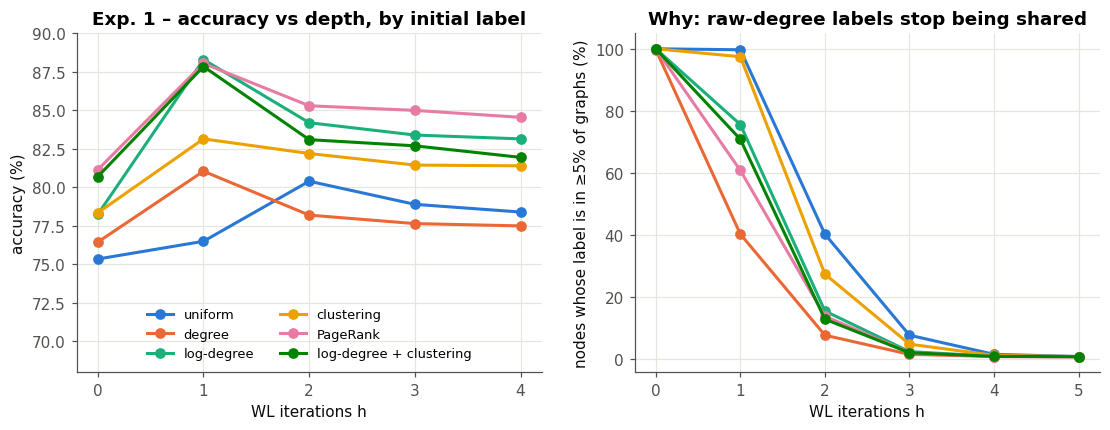

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (name, acc), col in zip(e1_curves.items(), PAL):
    ax[0].plot(range(0, 5), acc, "o-", color=col, label=name)
ax[0].set(xlabel="WL iterations h", ylabel="accuracy (%)", title="Exp. 1 – accuracy vs depth, by initial label",
          xticks=range(0, 5), ylim=(68, 90))
ax[0].legend(fontsize=8.5, loc="lower center", ncol=2)

for name, col in zip(INITS, PAL):
    s = label_stats[label_stats.init == name]
    ax[1].plot(s.h, 100 * s["common nodes"], "o-", color=col, label=name)
ax[1].set(xlabel="WL iterations h", ylabel="nodes whose label is in ≥5% of graphs (%)",
          title="Why: raw-degree labels stop being shared", xticks=range(0, H_MAX + 1))
fig.savefig(FIG_DIR / "02_exp1_initial_labels.png"); plt.show()

**What Experiment 1 shows.**

| initial labels | accuracy ($h$ tuned) | nodes with a label shared by ≥ 5% of graphs ($h=1$) |
|---|---|---|
| degree (textbook) | 81.05% | 40.2% |
| uniform | 80.40% | 99.7% *(but carries almost no information)* |
| clustering coefficient | 83.15% | 97.5% |
| **log-degree** | **88.30%** | 75.6% |
| PageRank (log-binned) | 88.05% | 60.8% |
| log-degree + clustering | 87.85% | 70.8% |

* **Binning the degree adds about 7 points**, the single biggest gain from changing one line of WL. The right panel explains why.
  With raw degree, after one iteration only **40%** of nodes carry a label that appears in at least 5% of graphs. A leaf attached
  to a hub of degree 336 gets the label `(1,{336})`, which probably exists in no other thread. With log-binned degree the same
  leaf gets `(1,{bin 9})`, shared by every thread with a big hub, so **76%** of nodes carry shareable labels.
  WL needs labels that **repeat across graphs**.
* Labels must also be **informative**. Uniform labels are perfectly shareable but carry no information. In fact uniform at depth
  $h+1$ behaves like degree at depth $h$ (uniform peaks at $h=2$ with 80.4%, degree at $h=1$ with 81.1%), because one WL step
  turns "all equal" into "degree".
* The clustering coefficient (Hamilton Eq. 2.5) helps a little but is zero for 92% of nodes, since REDDIT threads have few triangles.
  Adding it to log-degree does not improve on log-degree alone.
* PageRank bins work as well as log-degree. Both describe "how central a user is" on a coarse logarithmic scale, which is the
  information that matters here.

## 10. Experiment 2: relabelling rule and depth

Hamilton gives two versions of the relabelling step:

* **Eq. 2.6:** $l^{(i)}(v)=\mathrm{HASH}(\{\!\{l^{(i-1)}(u):u\in\mathcal N(v)\}\!\})$, which forgets the node's own label
* **Eq. 7.60:** $l^{(i)}(v)=\mathrm{HASH}(l^{(i-1)}(v),\{\!\{l^{(i-1)}(u):u\in\mathcal N(v)\}\!\})$, the standard 1-WL

**A small theorem.** *If the initial label is a function of the degree ($l^{(0)}(v)=f(d_v)$: uniform, degree, log-degree),
the two rules produce exactly the same partition at every iteration.*

*Proof sketch.* Write $M_i(v)=\{\!\{l^{(i)}(u):u\in\mathcal N(v)\}\!\}$. Unrolling Eq. 7.60 shows
$l^{(i)}(v)$ is a function of $\big(l^{(0)}(v), M_0(v),\dots,M_{i-1}(v)\big)$.
Each $l^{(i-1)}(u)$ determines all of $u$'s earlier labels, so $M_{i-1}(v)$ determines $M_0(v),\dots,M_{i-2}(v)$.
Its size is $d_v$, which determines $l^{(0)}(v)=f(d_v)$. So the neighbour multiset alone already contains the node's own label,
and adding it explicitly (Eq. 7.60) changes nothing. ∎

For labels that are **not** a function of degree (e.g. PageRank), Eq. 2.6 can lose information. We test both cases,
vary the depth $h=0\dots5$, and track the **label explosion**: how many distinct features WL creates.

In [17]:
# Check the theorem directly: identical histograms (up to renaming labels) => identical Gram matrices
for name in ["log-degree", "PageRank"]:
    same_all = all(np.array_equal(gram_linear(a), gram_linear(b)) for a, b in zip(FEATS[name], FEATS_NOSELF[name]))
    print(f"{name:10s}: Eq. 2.6 and Eq. 7.60 give identical kernels at every h? {same_all}")

e2_cols = {}
for name in ["log-degree", "PageRank"]:
    noself = [scaled(K) for K in cumulative(FEATS_NOSELF[name], gram_linear)]
    e2_cols[f"{name}: Eq. 7.60"] = [100 * evaluate({h: GRAMS_LIN[name][h]})["acc"] for h in range(H_MAX + 1)]
    e2_cols[f"{name}: Eq. 2.6"] = [100 * evaluate({h: noself[h]})["acc"] for h in range(H_MAX + 1)]
e2_cols["features (log-degree)"] = np.cumsum([b.shape[1] for b in FEATS["log-degree"]])
e2 = pd.DataFrame(e2_cols, index=pd.Index(range(H_MAX + 1), name="h"))
e2.to_csv(RES_DIR / "exp2_update_rule_depth.csv")
e2.round(2)

log-degree: Eq. 2.6 and Eq. 7.60 give identical kernels at every h? True


PageRank  : Eq. 2.6 and Eq. 7.60 give identical kernels at every h? False


,log-degree: Eq. 7.60,log-degree: Eq. 2.6,PageRank: Eq. 7.60,PageRank: Eq. 2.6,features (log-degree)
h,,,,,
0,78.25,78.25,81.15,81.15,13
1,88.30,88.30,88.05,88.30,15406
2,84.20,84.20,85.30,86.00,200213
3,83.40,83.40,85.00,85.70,501106
4,83.15,83.15,84.55,84.90,831265
5,82.75,82.75,84.15,84.60,1166712


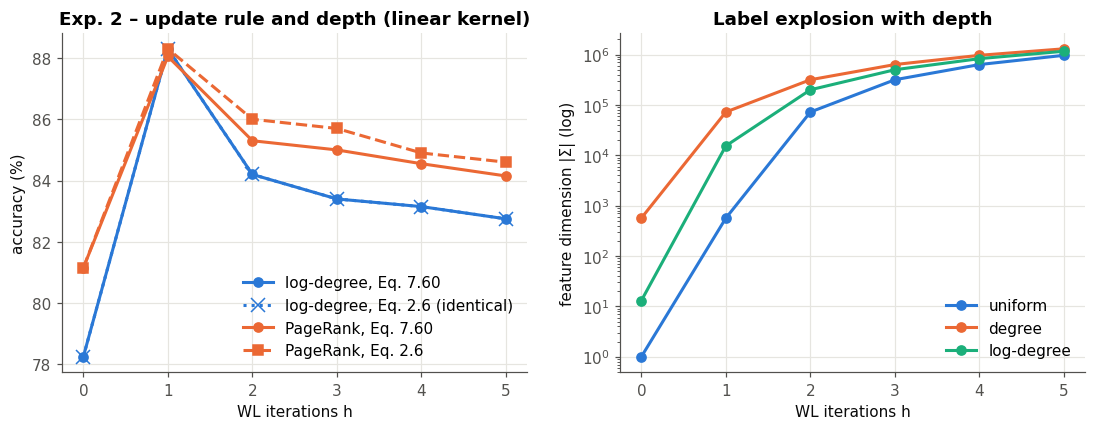

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(e2.index, e2["log-degree: Eq. 7.60"], "o-", color=PAL[0], label="log-degree, Eq. 7.60")
ax[0].plot(e2.index, e2["log-degree: Eq. 2.6"], "x:", color=PAL[0], ms=9, label="log-degree, Eq. 2.6 (identical)")
ax[0].plot(e2.index, e2["PageRank: Eq. 7.60"], "o-", color=PAL[1], label="PageRank, Eq. 7.60")
ax[0].plot(e2.index, e2["PageRank: Eq. 2.6"], "s--", color=PAL[1], label="PageRank, Eq. 2.6")
ax[0].set(xlabel="WL iterations h", ylabel="accuracy (%)", title="Exp. 2 – update rule and depth (linear kernel)")
ax[0].legend()
for name, col in zip(["uniform", "degree", "log-degree"], [PAL[0], PAL[1], PAL[2]]):
    ax[1].semilogy(range(H_MAX + 1), np.cumsum([b.shape[1] for b in FEATS[name]]), "o-", color=col, label=name)
ax[1].set(xlabel="WL iterations h", ylabel="feature dimension |Σ| (log)", title="Label explosion with depth")
ax[1].legend()
fig.savefig(FIG_DIR / "03_exp2_depth.png"); plt.show()

**What Experiment 2 shows.**
* **The theorem holds on real data.** With log-degree labels, Eq. 2.6 and Eq. 7.60 produce *identical* Gram matrices at every depth.
  The two curves lie on top of each other. With PageRank labels the rules differ, but only by under one point
  (e.g. 88.3% vs 88.05% at $h=1$), well within one standard deviation (about 2%).
* **Shallow is best on REDDIT.** Accuracy peaks at $h=1$ and slowly decays. Meanwhile the feature space explodes from
  13 labels ($h=0$) to 15k ($h=1$), 200k ($h=2$) and **1.17 million** ($h=5$). Deeper subtrees are almost all unique to one thread,
  so they dilute the kernel. For the final model, $h$ is still chosen by the inner cross-validation, not fixed by hand.

## 11. Experiment 3: how should two WL histograms be compared?

We keep log-degree labels and Eq. 7.60, and change only the kernel in Step 3. For the RBF kernel, the bandwidth
$\gamma\in\{\tfrac14,1,4\}\times\frac{1}{\mathrm{median}\lVert\phi-\phi'\rVert^2}$ is tuned in the inner loop.

In [19]:
def kernel_family(name, blocks, h_range=range(1, 5)):
    lin = cumulative(blocks, gram_linear)
    if name == "linear":
        return {h: scaled(lin[h]) for h in h_range}
    if name == "cosine":
        return {h: cosine_normalise(lin[h]) for h in h_range}
    if name == "intersection":
        inter = cumulative(blocks, gram_intersection)
        return {h: scaled(inter[h]) for h in h_range}
    if name == "RBF":
        return {(h, g): rbf_from_linear(lin[h], g) for h in h_range for g in (0.25, 1.0, 4.0)}

KERNELS = ["linear", "cosine", "intersection", "RBF"]
e3_curves, e3_rows, FAMILIES = {}, [], {}
for kname in KERNELS:
    fam = kernel_family(kname, FEATS["log-degree"]); FAMILIES[kname] = fam
    hs = sorted({k if isinstance(k, int) else k[0] for k in fam})
    e3_curves[kname] = [100 * evaluate({k: K for k, K in fam.items() if (k if isinstance(k, int) else k[0]) == h})["acc"]
                        for h in hs]
    r = evaluate(fam)
    e3_rows.append({"kernel": kname, "accuracy % (h, C, γ tuned)": 100 * r["acc"], "± std": 100 * r["std"], "F1": r["f1"]})
e3 = pd.DataFrame(e3_rows).set_index("kernel")
e3.to_csv(RES_DIR / "exp3_kernels.csv")
e3.round(2)

,"accuracy % (h, C, γ tuned)",± std,F1
kernel,,,
linear,88.30,1.89,0.89
cosine,84.65,2.25,0.85
intersection,90.15,2.40,0.90
RBF,90.90,2.17,0.91


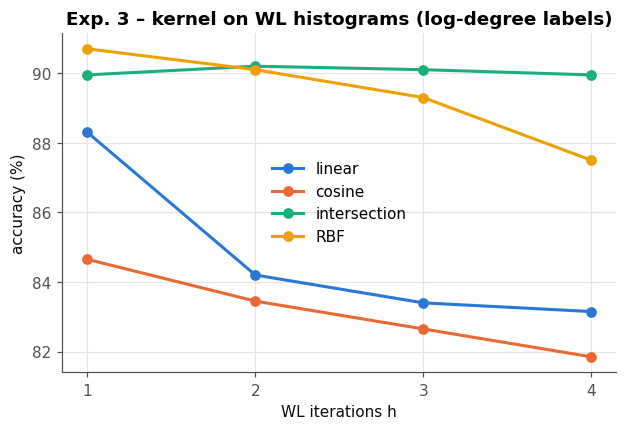

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for (kname, acc), col in zip(e3_curves.items(), PAL):
    ax.plot(range(1, 5), acc, "o-", color=col, label=kname)
ax.set(xlabel="WL iterations h", ylabel="accuracy (%)", title="Exp. 3 – kernel on WL histograms (log-degree labels)",
       xticks=range(1, 5))
ax.legend()
fig.savefig(FIG_DIR / "04_exp3_kernels.png"); plt.show()

**What Experiment 3 shows** (log-degree labels; $h$, $C$, $\gamma$ tuned in the inner loop):

| kernel on WL histograms | accuracy |
|---|---|
| cosine-normalised | 84.65% |
| linear (original) | 88.30% |
| histogram intersection (WL-OA) | 90.15% |
| **RBF** | **90.90%** |

* **Cosine normalisation hurts (−3.7 points).** It divides out the size of each histogram, but class −1 threads are about 3× larger,
  so size is part of the signal. A tweak that is standard elsewhere can backfire, and the dataset statistics explain why.
* **Intersection (+1.9) and RBF (+2.6) both beat the dot product.** The linear kernel multiplies counts, so two huge threads
  look very similar simply because both have many leaves, and big graphs dominate. $\min(c,c')$ (WL-OA) caps each pattern's
  contribution at what both graphs share. RBF measures *distance* $\lVert\phi-\phi'\rVert$, so graphs are similar only when their
  WL histograms are close, not merely when both are big.

## 12. Final ablation: from the textbook baseline to our best kernel

Now the definitive comparison, with **10-fold CV repeated 3 times (30 outer folds)**. Every setting tunes $h\in\{1,2,3,4\}$, $C$
(and $\gamma$ for RBF) in the inner loop. We change **one thing at a time**. As a sanity reference, we also include a classifier
that sees **only the graph size** (an RBF kernel on $\log|V|$) and the textbook *bag-of-nodes* degree histogram ($h=0$).

**Significance.** Outer folds share training data, so a plain paired t-test is over-confident. We use the
**corrected resampled t-test** (Nadeau & Bengio, 2003):
$$t=\frac{\bar d}{\sqrt{\left(\frac1k+\frac{n_{test}}{n_{train}}\right)\hat\sigma_d^2}},\qquad d_j=\mathrm{acc}^{\text{new}}_j-\mathrm{acc}^{\text{baseline}}_j,\quad k=30 .$$

In [21]:
from scipy import stats as st

logn = np.log(n_nodes)[:, None]
D_size = (logn - logn.T) ** 2
size_only = {g: np.exp(-g / np.median(D_size) * D_size) for g in (0.25, 1.0, 4.0)}

ABLATION = {
    "size only  (RBF on log|V|)":                  size_only,
    "bag of nodes  (degree histogram, h=0)":        {0: GRAMS_LIN["degree"][0]},
    "uniform labels + linear  (classic WL)":       {h: GRAMS_LIN["uniform"][h] for h in range(1, 5)},
    "BASELINE: degree + linear  (Hamilton)":        {h: GRAMS_LIN["degree"][h] for h in range(1, 5)},
    "+ log-degree labels":                          FAMILIES["linear"],
    "degree + RBF  (kernel change only)":          kernel_family("RBF", FEATS["degree"]),
    "log-degree + intersection (WL-OA)":           FAMILIES["intersection"],
    "OURS: log-degree + RBF":                       FAMILIES["RBF"],
}
RESULTS = {name: evaluate(k, n_repeats=3) for name, k in ABLATION.items()}

def corrected_ttest(a, b, n_train=1800, n_test=200):
    d = a - b; k = len(d)
    t = d.mean() / np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    return t, 2 * st.t.sf(abs(t), df=k - 1)

base = RESULTS["BASELINE: degree + linear  (Hamilton)"]["fold_acc"]
rows = []
for name, r in RESULTS.items():
    t, p = corrected_ttest(r["fold_acc"], base) if not name.startswith("BASELINE") else (np.nan, np.nan)
    rows.append({"setting": name, "accuracy %": 100 * r["acc"], "± std": 100 * r["std"], "F1": r["f1"],
                 "Δ vs baseline (pts)": 100 * (r["acc"] - base.mean()), "p-value": p,
                 "most chosen (setting, C)": r["chosen"].most_common(1)[0][0], "CV time (s)": r["seconds"]})
ablation = pd.DataFrame(rows).set_index("setting")
ablation.to_csv(RES_DIR / "final_ablation.csv")
ablation.style.format({"accuracy %": "{:.2f}", "± std": "{:.2f}", "F1": "{:.3f}", "Δ vs baseline (pts)": "{:+.2f}",
                       "p-value": "{:.1e}", "CV time (s)": "{:.0f}"})

,accuracy %,± std,F1,Δ vs baseline (pts),p-value,"most chosen (setting, C)",CV time (s)
setting,,,,,,,
size only (RBF on log|V|),77.33,3.10,0.778,-4.42,2.2e-04,"(4.0, 1000.0)",472
"bag of nodes (degree histogram, h=0)",76.67,2.73,0.774,-5.08,4.8e-04,"(0, 10000.0)",109
uniform labels + linear (classic WL),80.90,2.38,0.819,-0.85,1.7e-01,"(2, 1000.0)",181
BASELINE: degree + linear (Hamilton),81.75,2.46,0.826,+0.00,nan,"(1, 1000.0)",60
+ log-degree labels,88.10,1.71,0.889,+6.35,1.1e-08,"(1, 1000.0)",154
degree + RBF (kernel change only),85.08,2.31,0.855,+3.33,6.5e-04,"((1, 1.0), 100)",110
log-degree + intersection (WL-OA),90.03,1.79,0.903,+8.28,7.2e-10,"(3, 100)",32
OURS: log-degree + RBF,90.72,1.83,0.910,+8.97,3.3e-11,"((1, 1.0), 100)",109


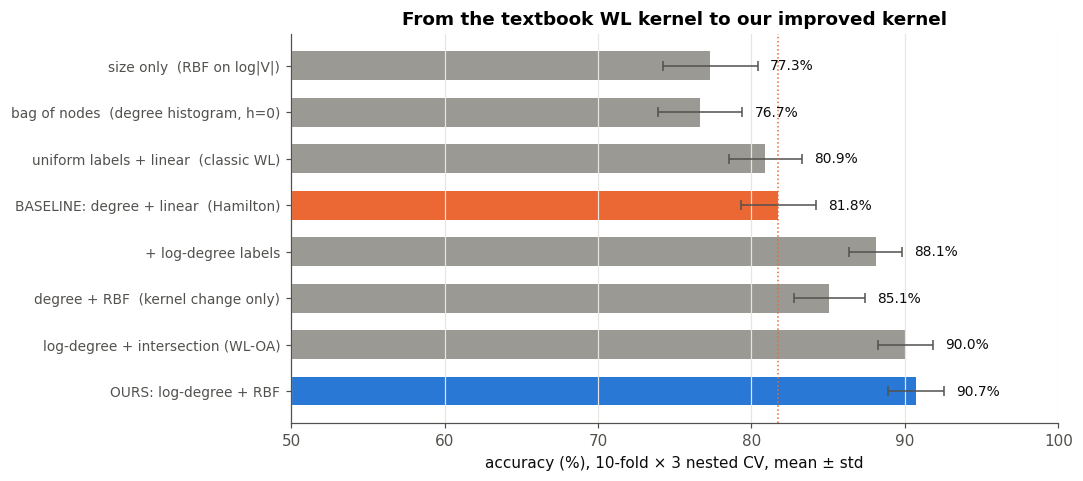

In [22]:
order = list(RESULTS)
acc = np.array([100 * RESULTS[k]["acc"] for k in order]); sd = np.array([100 * RESULTS[k]["std"] for k in order])
colors = [GREY] * len(order)
colors[order.index("BASELINE: degree + linear  (Hamilton)")] = PAL[1]
colors[order.index("OURS: log-degree + RBF")] = PAL[0]

fig, ax = plt.subplots(figsize=(9, 4.6))
yy = np.arange(len(order))[::-1]
ax.barh(yy, acc, xerr=sd, color=colors, height=0.62, error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 3})
for yi, a, e in zip(yy, acc, sd):
    ax.text(a + e + 0.8, yi, f"{a:.1f}%", va="center", fontsize=9, color="#0b0b0b")
ax.set_yticks(yy, order, fontsize=9)
ax.set(xlim=(50, 100), xlabel="accuracy (%), 10-fold × 3 nested CV, mean ± std",
       title="From the textbook WL kernel to our improved kernel")
ax.axvline(100 * base.mean(), color=PAL[1], lw=1, ls=":")
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "05_ablation.png"); plt.show()

**The headline result** (30 outer folds, all hyper-parameters chosen by inner CV):

| step | accuracy | change vs. baseline | corrected p-value |
|---|---|---|---|
| graph size only (reference) | 77.33% | −4.42 | — |
| bag of nodes, $h=0$ (Hamilton §2.1.2) | 76.67% | −5.08 | — |
| **textbook WL: degree + linear** | **81.75% ± 2.46** | baseline | — |
| change labels only: log-degree + linear | 88.10% | **+6.35** | 1.1e-08 |
| change kernel only: degree + RBF | 85.08% | +3.33 | 6.5e-04 |
| log-degree + intersection (WL-OA) | 90.03% | +8.28 | 7.2e-10 |
| **ours: log-degree + RBF** | **90.72% ± 1.83** | **+8.97** | 3.3e-11 |

* The two modifications are **complementary**. Labels alone add +6.4, the kernel alone +3.3, and together +9.0 points. The error
  rate drops from 18.3% to 9.3%, **49% fewer mistakes**, with a smaller fold-to-fold spread (std 2.46 → 1.83).
* Every improvement is significant under the conservative corrected resampled t-test, while classic uniform-label WL is not
  significantly different from the textbook baseline (p = 0.17), as the "uniform = degree shifted by one step" argument predicts.
* Size alone gives 77%, and the full model adds about **13 points** on top of it, so the improvement comes from **structure** learned by WL,
  not from counting nodes.

## 13. Why it works: visual intuition

### 13.1 WL colour refinement on real threads
Two small threads, one from each class, coloured by their WL label at iterations 0, 1 and 2 (log-degree initial labels).
Same colour means same rooted-subtree pattern. Colours are shared across the two graphs, because the HASH table is shared.

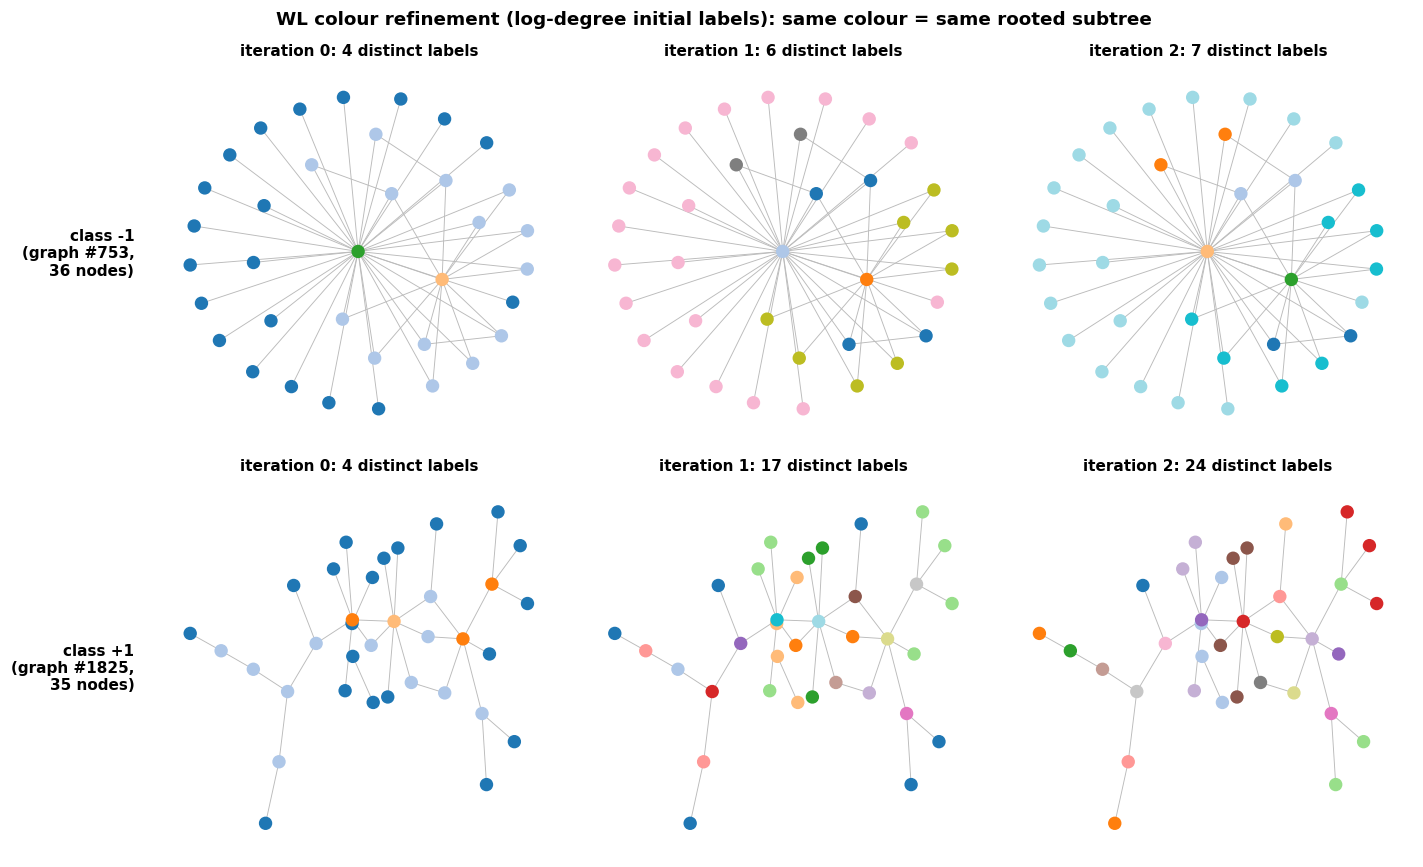

In [23]:
def pick(c, lo=25, hi=45):
    cand = np.where((y == c) & (n_nodes >= lo) & (n_nodes <= hi))[0]
    return int(cand[np.argmax(max_deg[cand] / n_nodes[cand])]) if c == -1 else int(cand[np.argmin(max_deg[cand] / n_nodes[cand])])

examples = [pick(-1), pick(1)]
_, lab_all = wl_features(init_log_degree(), 2)
cmap = plt.get_cmap("tab20")
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for row, g in enumerate(examples):
    nodes = np.where(graph_of == g)[0]
    Gx = nx.Graph(); Gx.add_nodes_from(nodes); Gx.add_edges_from((u, v) for u in nodes for v in nbrs[u] if u < v)
    pos = nx.kamada_kawai_layout(Gx)
    for it in range(3):
        lab = lab_all[it][nodes]
        uniq = {l: k for k, l in enumerate(np.unique(lab_all[it][np.isin(graph_of, examples)]))}
        nx.draw_networkx(Gx, pos, ax=axes[row, it], with_labels=False, node_size=60, width=0.6, edge_color="#bbbbbb",
                         node_color=[cmap(uniq[l] % 20) for l in lab])
        axes[row, it].set_title(f"iteration {it}: {len(set(lab))} distinct labels", fontsize=10)
        axes[row, it].axis("off")
    axes[row, 0].text(-0.05, 0.5, f"class {y[g]:+d}\n(graph #{g},\n{len(nodes)} nodes)", transform=axes[row, 0].transAxes,
                      ha="right", va="center", fontsize=10, fontweight="bold")
fig.suptitle("WL colour refinement (log-degree initial labels): same colour = same rooted subtree", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_wl_refinement.png"); plt.show()

**Reading the picture.** The class −1 thread is **star-shaped**: a couple of hub users reply to almost everyone. WL needs only
6–7 labels to describe it, and most nodes share the label "leaf attached to a big hub". The class +1 thread is a **branching
conversation** with chains of replies. Already at iteration 1 it splits into 17 different rooted subtrees. These differences in
*how many* nodes have *which* local shape are exactly what the WL histogram $\phi(G)$ counts.

### 13.2 What the kernels "see"
**Top: Gram matrices.** Graphs are sorted by class, and by size within each class. Bright means similar.
**Bottom: SVM decision values** $f(G)=\sum_j\alpha_jy_j\,k(G_j,G)+b$ for every graph, computed while that graph was in a
held-out test fold. The sign of $f(G)$ is the prediction, so the further the two class histograms sit from 0 on opposite sides,
the more confidently and correctly the kernel separates them.

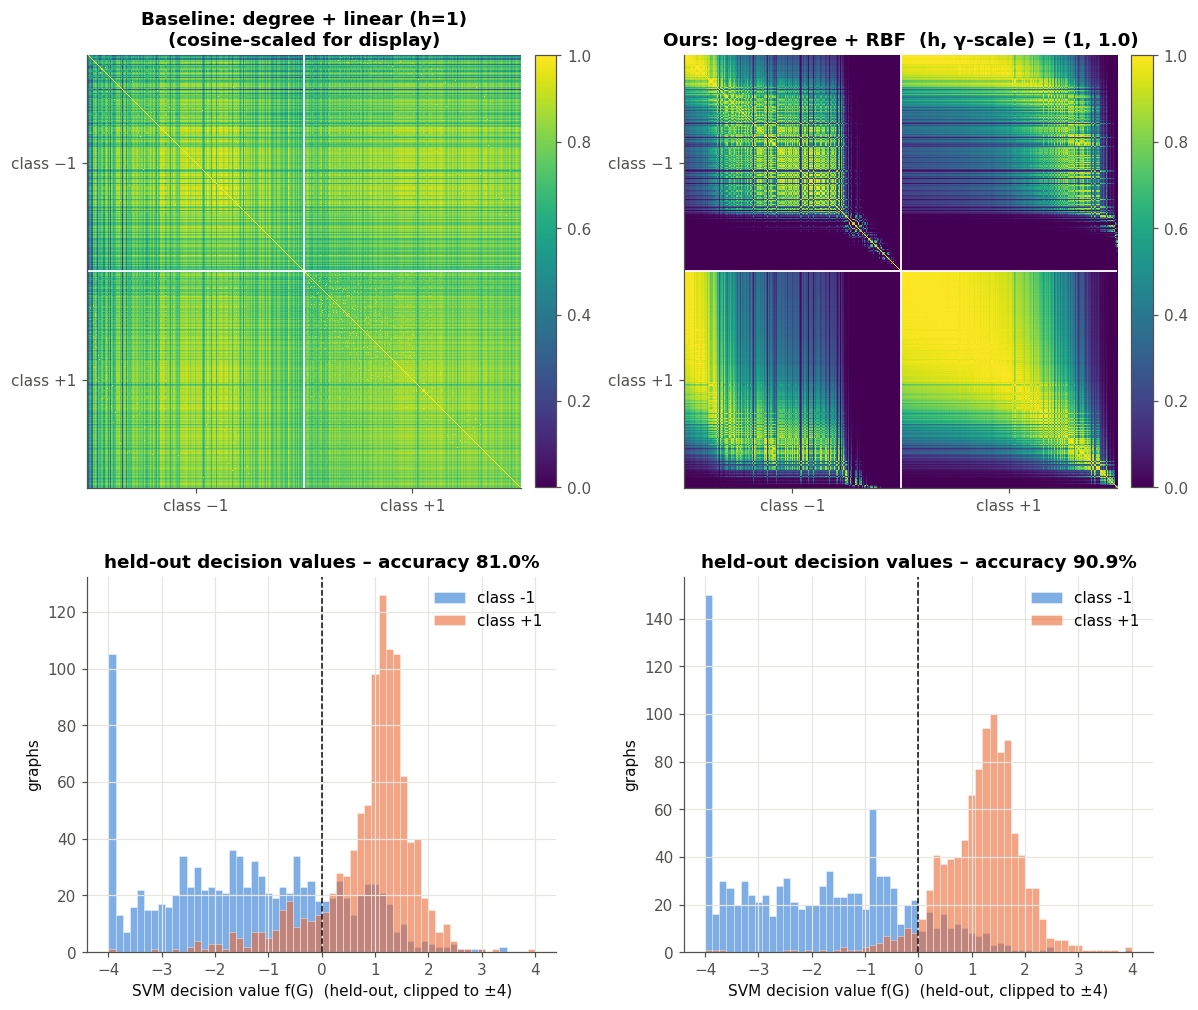

In [24]:
def best_gram(name):
    key = RESULTS[name]["chosen"].most_common(1)[0][0][0]
    return ABLATION[name][key], key

K_base, kb = best_gram("BASELINE: degree + linear  (Hamilton)")
K_ours, ko = best_gram("OURS: log-degree + RBF")
order_idx = np.lexsort((n_nodes, y))                                  # by class, then by graph size

fig, ax = plt.subplots(2, 2, figsize=(11, 9.5), gridspec_kw={"height_ratios": [1.15, 0.85]})
panels = [("BASELINE: degree + linear  (Hamilton)", cosine_normalise(K_base), f"Baseline: degree + linear (h={kb})\n(cosine-scaled for display)"),
          ("OURS: log-degree + RBF", K_ours, f"Ours: log-degree + RBF  (h, γ-scale) = {ko}")]
for col, (name, K, title) in enumerate(panels):
    im = ax[0, col].imshow(K[np.ix_(order_idx, order_idx)], cmap="viridis", interpolation="nearest")
    ax[0, col].axhline(999.5, color="w", lw=1.2); ax[0, col].axvline(999.5, color="w", lw=1.2)
    ax[0, col].set(title=title, xticks=[500, 1500], xticklabels=["class −1", "class +1"],
                   yticks=[500, 1500], yticklabels=["class −1", "class +1"])
    ax[0, col].grid(False); fig.colorbar(im, ax=ax[0, col], fraction=0.046, pad=0.03)

    f = RESULTS[name]["score"][0]
    f = np.clip(f, -4, 4)
    bins = np.linspace(-4, 4, 61)
    for c, colr in zip([-1, 1], PAL):
        ax[1, col].hist(f[y == c], bins=bins, color=colr, alpha=0.6, label=f"class {c:+d}", edgecolor="white", linewidth=0.4)
    ax[1, col].axvline(0, color="#0b0b0b", lw=1, ls="--")
    acc_here = np.mean(np.where(f > 0, 1, -1) == y)
    ax[1, col].set(xlabel="SVM decision value f(G)  (held-out, clipped to ±4)", ylabel="graphs",
                   title=f"held-out decision values – accuracy {acc_here:.1%}")
    ax[1, col].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "07_gram_decision.png"); plt.show()

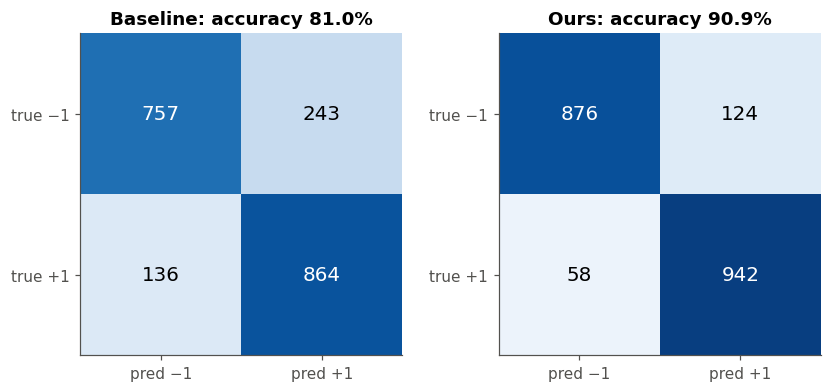

In [25]:
def confusion(y_true, y_pred):
    return np.array([[np.sum((y_true == a) & (y_pred == b)) for b in (-1, 1)] for a in (-1, 1)])

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, name, title in [(ax[0], "BASELINE: degree + linear  (Hamilton)", "Baseline"), (ax[1], "OURS: log-degree + RBF", "Ours")]:
    Cm = confusion(y, RESULTS[name]["pred"][0])                     # repetition 1: every graph predicted exactly once
    a.imshow(Cm, cmap="Blues", vmin=0, vmax=1000); a.grid(False)
    for i in range(2):
        for j in range(2):
            a.text(j, i, Cm[i, j], ha="center", va="center", fontsize=13, color="white" if Cm[i, j] > 500 else "black")
    a.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["pred −1", "pred +1"], yticklabels=["true −1", "true +1"],
          title=f"{title}: accuracy {np.trace(Cm) / Cm.sum():.1%}")
fig.savefig(FIG_DIR / "08_confusion.png"); plt.show()

**Reading the kernels.**
* **Baseline Gram matrix (top left):** almost uniformly bright. Every thread looks fairly similar to every other, so there is
  little class structure for the SVM to use.
* **Our Gram matrix (top right):** clear **block structure**. Class +1 threads (bottom-right block) are highly similar to each
  other. The large class −1 threads are similar mainly to one another and almost orthogonal to class +1. Only the *smallest*
  class −1 threads still resemble class +1 threads (bright strip in the bottom-left block). Small threads carry less structure,
  so they are the hardest to separate.
* **Decision values (bottom):** with our kernel the two histograms are pushed apart on either side of $f(G)=0$, with far less overlap
  around zero.
* **Confusion matrices** (first CV repetition, each graph predicted once while held out): total errors fall from **379** to **182**.
  Both kinds of mistake are cut roughly in half (243 → 124 and 136 → 58).

## 14. Summary of results (computed above)

In [26]:
b = RESULTS["BASELINE: degree + linear  (Hamilton)"]; o = RESULTS["OURS: log-degree + RBF"]
s = RESULTS["size only  (RBF on log|V|)"]; l = RESULTS["+ log-degree labels"]; d = RESULTS["degree + RBF  (kernel change only)"]
print(f"Graph size alone ............................ {100*s['acc']:.2f}%")
print(f"Textbook WL baseline (degree, linear) ........ {100*b['acc']:.2f}% ± {100*b['std']:.2f}")
print(f"  + log-binned degree labels ................. {100*l['acc']:.2f}%  ({100*(l['acc']-b['acc']):+.2f} pts)")
print(f"  RBF kernel only (degree labels) ............ {100*d['acc']:.2f}%  ({100*(d['acc']-b['acc']):+.2f} pts)")
print(f"  both: log-degree + RBF (OURS) .............. {100*o['acc']:.2f}% ± {100*o['std']:.2f}  ({100*(o['acc']-b['acc']):+.2f} pts)")
print(f"Relative error reduction vs baseline ......... {100*(1-(1-o['acc'])/(1-b['acc'])):.1f}%")
print(f"Total notebook runtime ....................... {(time.time()-T_START)/60:.1f} min")

Graph size alone ............................ 77.33%
Textbook WL baseline (degree, linear) ........ 81.75% ± 2.46
  + log-binned degree labels ................. 88.10%  (+6.35 pts)
  RBF kernel only (degree labels) ............ 85.08%  (+3.33 pts)
  both: log-degree + RBF (OURS) .............. 90.72% ± 1.83  (+8.97 pts)
Relative error reduction vs baseline ......... 49.1%
Total notebook runtime ....................... 60.5 min


## 15. Limitations, conclusion and references

**Conclusion.** We re-implemented the Weisfeiler-Lehman subtree kernel from first principles and verified it against the
textbook's worked example, a known failure case, permutation invariance, and an independent implementation. On REDDIT-BINARY, the
textbook version (degree labels, linear kernel) reaches 81.75%. Two principled modifications that keep the WL algorithm unchanged lift
this to **90.72%** (+9.0 points, 49% fewer errors, p ≈ 3e-11):
1. **log-binned degree as the initial label**, so that WL labels are shared across graphs, and
2. **an RBF kernel on the WL histograms**, which compares graphs by the distance between their subtree counts instead of a raw dot product.

Along the way we found that cosine normalisation hurts here because graph size is informative, that deeper WL is not better on these
tree-like graphs, and that Hamilton's two update rules (Eq. 2.6 and 7.60) are provably identical whenever the initial labels depend only on degree.

**Limitations.**
* 1-WL cannot count triangles or cycles (Test 2, Hamilton Fig. 7.3). REDDIT threads are tree-like, so this costs little here,
  but on chemistry or social graphs with many triangles a $k$-WL or substructure-augmented kernel (Hamilton §7.3.5) would be needed.
* RBF and intersection kernels need a dense $|\mathcal G|\times|\mathcal G|$ Gram matrix. That is fine for 2,000 graphs, but at
  100k graphs one would switch to explicit features with a linear model.
* Graph size is a strong confounder on this dataset. We report a size-only reference so the gain from structure is visible separately.

**References**
1. W. L. Hamilton. *Graph Representation Learning*. Morgan & Claypool, 2020: §2.1.2 (Eq. 2.5, 2.6), §7.3 (Eq. 7.60, Fig. 7.2, 7.3).
2. N. Shervashidze, P. Schweitzer, E. J. van Leeuwen, K. Mehlhorn, K. M. Borgwardt. Weisfeiler-Lehman Graph Kernels. *JMLR* 12, 2011.
3. N. M. Kriege, P.-L. Giscard, R. C. Wilson. On Valid Optimal Assignment Kernels and Applications to Graph Classification. *NeurIPS* 2016.
4. P. Yanardag, S. V. N. Vishwanathan. Deep Graph Kernels. *KDD* 2015 (REDDIT-BINARY).
5. C. Morris et al. TUDataset: A collection of benchmark datasets for learning with graphs. 2020.
6. C. Nadeau, Y. Bengio. Inference for the Generalization Error. *Machine Learning* 52, 2003.
7. L. Page, S. Brin, R. Motwani, T. Winograd. The PageRank Citation Ranking. 1999.